# Augmentations in datasets

Transforms are attached to the outputs of a dataset : one transform per output, matched with the output pattern.
This notebook shows :

- transforms on single, tuple and dict outputs ;
- multi-view outputs (several augmented views of the same chunk, e.g. for contrastive learning) ;
- the order of features and transforms, in workers and with batch features ;
- transforms applied on batches (`batch_transforms`), e.g. on GPU.

In [1]:
import math, tempfile
from pathlib import Path
import numpy as np
import soundfile as sf
import torch
import matplotlib.pyplot as plt
from acids_dataset import transforms as adt
from acids_dataset import features as F
from acids_dataset.datasets import AudioDataset

SR = 16000
torch.manual_seed(0)
root = Path(tempfile.mkdtemp()) / "tones"
root.mkdir()
t = torch.arange(3 * SR) / SR
for i, f0 in enumerate([110, 147, 196, 262, 349, 466]):
    x = sum(0.3 / k * torch.sin(2 * math.pi * f0 * k * t) for k in range(1, 10)) * (0.6 + 0.4 * torch.sin(2 * math.pi * 0.5 * t))
    sf.write(root / f"tone_{i}.wav", x.numpy(), SR)

## Transforms and output patterns

For a single output, `transforms` is a transform ; for tuples, a list (one per output, and the list can be shorter
than the tuple : its transforms apply to the first outputs) ; for dicts, a dict whose keys are output names (after
aliases), and outputs without key are not transformed.

In [2]:
augment = adt.Compose(adt.RandomEQ(p=0.8, sr=SR), adt.Gain(p=0.8, sr=SR), adt.PolarityInversion(p=0.5, sr=SR))

single = AudioDataset(root, sr=SR, chunk_length=1., transforms=augment)
pair = AudioDataset(root, sr=SR, chunk_length=1., features=[F.RMS(sr=SR)], output_pattern="(waveform,rms)",
                    transforms=[augment])
named = AudioDataset(root, sr=SR, chunk_length=1., features=[F.RMS(sr=SR)], output_pattern="{waveform->x,rms->y}",
                     transforms={"x": augment, "y": lambda r: (r + 100) / 100})          # any callable is a transform
print(tuple(single[0].shape), [tuple(o.shape) for o in pair[0]], {k: tuple(v.shape) for k, v in named[0].items()})

(1, 16000) [(1, 16000), (7,)] {'x': (1, 16000), 'y': (1, 7)}


Transforms can also be given to `get`, or changed later with `dataset.transforms` :

In [3]:
y = single.get(0, "waveform", adt.Reverse(sr=SR))
single.transforms = adt.Mute(p=1., sr=SR)
print("muted :", single[0].abs().max().item() < 1e-3)

muted : True


## Multi-view outputs

The same field can be given several times in an output pattern, with aliases : each view gets its own transforms.
All views come from the **same chunk** : here, a clean target and two augmented views (for denoising or contrastive
objectives).

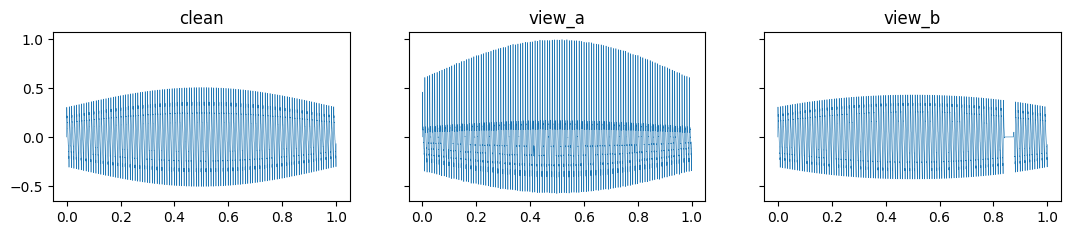

In [4]:
views = AudioDataset(root, sr=SR, chunk_length=1., output_pattern="{waveform->clean,waveform->view_a,waveform->view_b}",
                     transforms={"view_a": adt.Compose(adt.AddGaussianSNR(sr=SR), adt.RandomEQ(sr=SR)),
                                 "view_b": adt.Compose(adt.TanhDistortion(sr=SR), adt.TimeMask(sr=SR))})
item = views[2]
fig, axes = plt.subplots(1, 3, figsize=(13, 2.2), sharey=True)
for ax, (name, w) in zip(axes, item.items()):
    ax.plot(torch.arange(w.shape[-1]) / SR, w[0], lw=0.4); ax.set_title(name)
plt.show()

## Features and transforms

By default, features are computed **after** transforms : they describe the augmented audio, i.e. the waveform output after
its transforms. This holds for features computed item by item in workers, and for `batch_features` computed in the main
process. With `features_after_transforms=False` (in the dataset constructor, `configure` or `get_loader`), features are
computed on the loaded audio, **before** transforms, and describe the original audio. With a gain transform, the loudness
feature follows the gain only in the first case :

Pre-processed datasets read their features from the database : these always describe the original audio (only batch
features follow `features_after_transforms`).

In [ ]:
quiet = adt.Lambda(lambda y, sample_rate: 0.1 * y, sr=SR)                  # -20 dB
dataset = AudioDataset(root, sr=SR, chunk_length=1., features=[F.Loudness(keep_channels=False, sr=SR)],
                       output_pattern="{waveform,loudness}", transforms={"waveform": quiet})
loudness = F.Loudness(keep_channels=False, sr=SR)

after = next(iter(dataset.get_loader(batch_size=6, seed=0)))
after_batch = next(iter(dataset.get_loader(batch_size=6, seed=0, batch_features=["loudness"], device="cpu")))
before = next(iter(dataset.get_loader(batch_size=6, seed=0, features_after_transforms=False)))
print("loudness of transformed waveforms         :", loudness.batch_call(after["waveform"]).flatten().round().tolist())
print("loudness feature (default, after)         :", after["loudness"].flatten().round().tolist())
print("loudness feature (batch_features, after)  :", after_batch["loudness"].flatten().round().tolist())
print("loudness feature (before transforms)      :", before["loudness"].flatten().round().tolist())

## Transforms on batches

With `batch_transforms=True`, transforms are applied on whole batches on `device` in the main process, instead of item
by item in workers. Torch-based transforms then run on the accelerator (numpy-based ones move batches to the CPU
and back). Note that random decisions are then drawn per item (`rand_batchwise=True`) or per batch.

In [6]:
device = "cuda" if torch.cuda.is_available() else "cpu"
dataset = AudioDataset(root, sr=SR, chunk_length=1., output_pattern="{waveform}",
                       transforms={"waveform": adt.Compose(adt.Mute(p=0.5, sr=SR), adt.PreEmphasis(sr=SR))})
loader = dataset.get_loader(batch_size=8, batch_transforms=True, batch_features=[], device=device, seed=0)
batch = next(iter(loader))
print(batch["waveform"].device, "muted items :", (batch["waveform"].abs().amax(-1) < 1e-3).flatten().int().tolist())

cpu muted items : [1, 1, 0, 0, 0, 1, 0, 0]


## Variable lengths : stretch and crop

Some transforms change the length of the signal (`Stretch`, `RoomSimulator`...). Load
longer chunks and crop them back to a fixed size with `Crop`, such that items can be batched :

In [7]:
stretch = adt.Compose(adt.Stretch(p=1., sr=SR), adt.Crop(SR // 2, pad_if_shorter="zero", sr=SR))
dataset = AudioDataset(root, sr=SR, chunk_length=1., transforms=stretch)
print([tuple(dataset[i].shape) for i in range(4)], tuple(next(iter(dataset.get_loader(batch_size=4))).shape))

[(1, 8000), (1, 8000), (1, 8000), (1, 8000)] (4, 1, 8000)
